# **Part 1: Visualization & Exploratory Data Analysis (EDA)**

### **Dataset Introduction**

In this project, we will work with the Palmer Penguins dataset, which contains measurements of penguins observed on islands near Antarctica.

Please download the dataset [penguins.csv](https://drive.google.com/file/d/1dv8A8v_sdf29p1At40S7KBslJPmBA3e9/view?usp=sharing) or from canvas.

### **Dataset Description**

Each row represents a penguin, and columns include:

- species – Penguin species
- island – Island where the penguin was found
- bill_length_mm – Bill length (mm)
- bill_depth_mm – Bill depth (mm)
- flipper_length_mm – Flipper length (mm)
- body_mass_g – Body mass (grams)
- sex – Sex of the penguin

Some values are missing, which makes this dataset ideal for practicing missing data handling.



Your task is to perform a comprehensive Exploratory Data Analysis (EDA) and visualization on the Palmer Penguins dataset. This project aims to deepen your understanding of data characteristics, relationships between variables, and effective data presentation using Python's data science libraries.

**Instructions:**

1.  **Load the Dataset:** Begin by loading the `penguins.csv` dataset into a pandas DataFrame.
2.  **Initial Data Inspection:** Perform an initial inspection to understand the dataset's structure. Display the first few rows, check data types and non-null values, and generate descriptive statistics.
3.  **Handle Missing Values:** Identify and address any missing values in the dataset. Clearly explain your chosen strategy for handling missing data (e.g., imputation, dropping rows/columns) and justify your decision.
4.  **Perform EDA and Visualization:** Conduct a thorough EDA, exploring distributions, relationships, and patterns within the data. You are required to use **at least three distinct types of visualizations** (e.g., histograms, scatter plots, box plots, bar charts). For each visualization:
    *   Justify your choice of plot type, explaining why it is suitable for the variables being analyzed.
    *   Clearly articulate what insights each visualization reveals about the data (e.g., distributions, correlations, outliers, group differences).
5.  **Summarize Key Findings:** Based on your EDA and visualizations, summarize the most important insights and observations about the Palmer Penguins dataset. Highlight any discovered patterns, trends, anomalies, or interesting relationships.
6.  **Final Task:** Present your complete EDA and visualization analysis, emphasizing key takeaways and interpretations of the observed data characteristics and relationships in a clear and concise manner.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [24]:
print("Missing columns:")
print(df.isnull().sum())
df_clean = df.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']).copy()
df_clean['sex'] = df_clean.groupby('species')['sex'].transform(lambda x: x.fillna(x.mode()[0]))
print(df_clean.isnull().sum())
print(df_clean)

Missing columns:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
4    Adelie  Torgersen            36.7           19.3              193.0   
5    Adelie  Torgersen            39.3           20.6              190.0   
..      ...        ...             ...            ...                ...   
338  Gentoo     Biscoe            47.2           13.7              214.0   
340  Gentoo     Bisc

In [25]:
df_clean = df_clean.reset_index(drop=True)
df_clean

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
337,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
338,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
339,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
340,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


Rows missing all physical measurements (2 rows) were dropped because they carry no numerical value for analysis and make up less than 1% of the dataset.

Missing values in sex (10 rows) were imputed using the mode (most frequent category) grouped by species so we retain those rows without losing valuable measurement data.


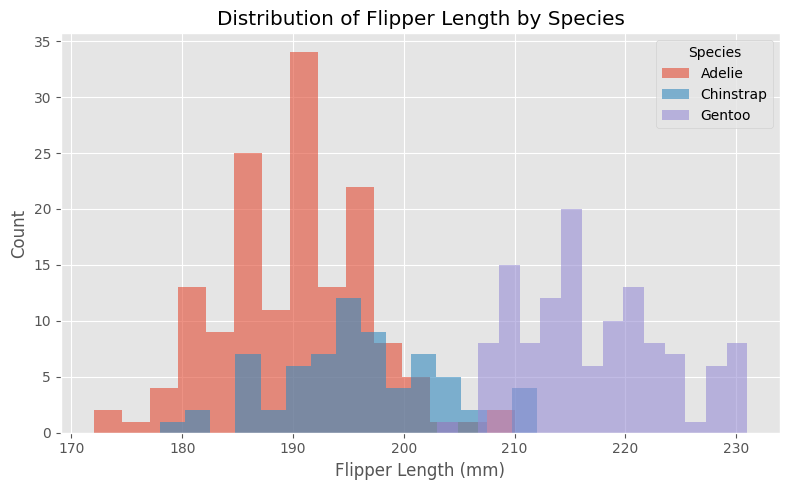

In [30]:
plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(8,5))
for species, group in df_clean.groupby('species'):
    ax.hist(group['flipper_length_mm'], alpha=0.6, label=species, bins=15)

ax.set_title("Distribution of Flipper Length by Species")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Count")
ax.legend(title="Species")
plt.tight_layout()
plt.show()

Gentoo penguins have noticeably longer flippers (peaking around 210–225 mm) compared to Adelie and Chinstrap penguins, whose flipper lengths largely overlap around 190 mm. Gentoo however seem to be less common than Adelie, but not as uncommon as Chinstrap.

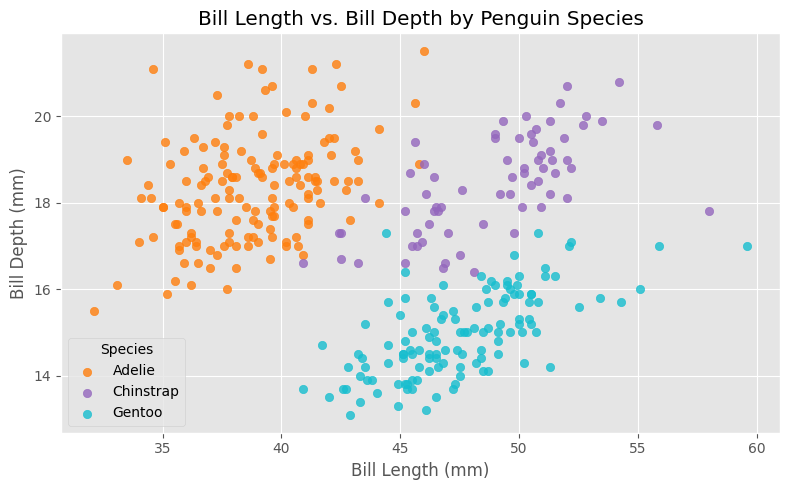

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {'Adelie': 'tab:orange', 'Chinstrap': 'tab:purple', 'Gentoo': 'tab:cyan'}
for species, group in df_clean.groupby('species'):
    ax.scatter(group['bill_length_mm'], group['bill_depth_mm'],
               label=species, color=colors[species], alpha=0.8)

ax.set_title("Bill Length vs. Bill Depth by Penguin Species")
ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.legend(title="Species")
plt.tight_layout()
plt.show()

Insights Revealed: Clear cluster separation exists between species. Gentoo penguins have relatively long but shallow bills, whereas Adelie penguins have shorter, deeper bills. Within each individual species cluster, bill length and bill depth share a positive correlation (Simpson's Paradox).

/tmp/ipykernel_576/3249608189.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(body_mass_data, labels=species_list)


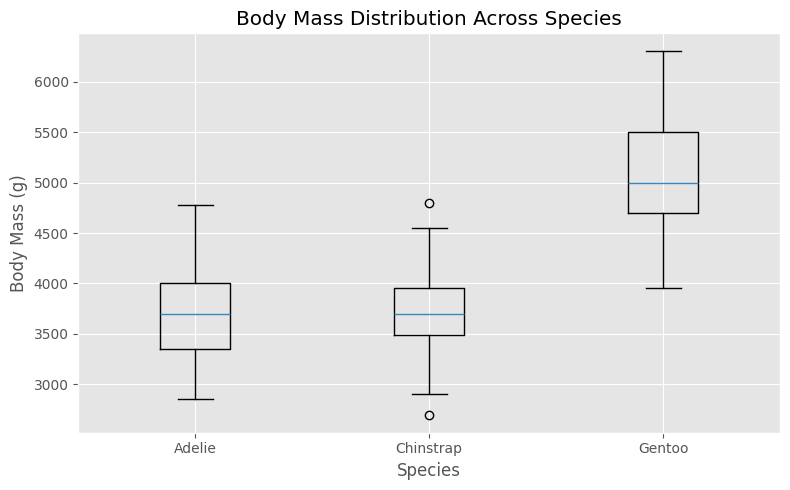

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))

# Prepare body mass arrays per species
species_list = df_clean['species'].unique()
body_mass_data = [df_clean[df_clean['species'] == sp]['body_mass_g'] for sp in species_list]

# Create standard box plot
ax.boxplot(body_mass_data, labels=species_list)

ax.set_title("Body Mass Distribution Across Species")
ax.set_xlabel("Species")
ax.set_ylabel("Body Mass (g)")
plt.tight_layout()
plt.show()

Gentoo penguins are significantly heavier (median body mass about 5,000g) than Adelie and Chinstrap penguins, both of which share a similar median body mass of about 3,700g.

Profile descriptions: Gentoo penguins form a distinct biological group characterized by significantly higher body mass and longer flipper lengths compared to the other two species. They also happen to less common.

Separability via Bill Dimensions: Adelie and Chinstrap penguins are similar in body mass and flipper length, but can be distinguished by bill length (Chinstraps have substantially longer bills than Adelies).

Location & Species Diversity: Biscoe Island hosts the largest penguins (Gentoos), whereas Adelie penguins are distributed across all three islands.

**TAKEAWAYS**
Gentoo is the largest species by overall physical size (mass > 4,500g, flippers > 210mm).

Chinstrap penguins match Adelies in overall body mass, but mirror Gentoos in having longer bills.

Adelie penguins represent the most compact species in bill length while having shorter bills relative to their size.